In [16]:
import os

# Define local project root in Colab
PROJECT_DIR = '/content/refusal_prediction'

# Create the required folder structure
folders = [
    'data',
    'notebooks',
    'outputs',
    'models',
    'dashboard',
    'documents'
]

for folder in folders:
    os.makedirs(os.path.join(PROJECT_DIR, folder), exist_ok=True)

print(f"Local project structure created at: {PROJECT_DIR}")

Local project structure created at: /content/refusal_prediction


In [17]:
import pandas as pd
import numpy as np
import os

# Define paths
DATA_DIR = '/content/refusal_prediction/data'

print("Loading datasets...")
prev_app = pd.read_csv(os.path.join(DATA_DIR, '/content/previous_application.csv'))
app_train = pd.read_csv(os.path.join(DATA_DIR, '/content/application_train.csv'))

print(f"Original previous_application shape: {prev_app.shape}")
print(f"Original application_train shape: {app_train.shape}")

# 1. Target Construction & Filtering
# Keep only Approved and Refused
valid_statuses = ['Approved', 'Refused']
prev_app = prev_app[prev_app['NAME_CONTRACT_STATUS'].isin(valid_statuses)].copy()

# Create binary target: Refused = 1, Approved = 0
prev_app['REFUSED'] = (prev_app['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)

refusal_rate = prev_app['REFUSED'].mean()
print(f"\nFiltered previous_application shape: {prev_app.shape}")
print(f"Actual Refusal Rate: {refusal_rate:.4%}")

# 2. Handle Placeholders (e.g., 365243 in DAYS_* columns)
days_cols = [col for col in prev_app.columns if 'DAYS' in col]
for col in days_cols:
    # Replace 365243 with NaN as it represents an eternity / missing value placeholder
    prev_app[col] = prev_app[col].replace(365243, np.nan)

# 3. Join client attributes to applications using SK_ID_CURR
print("\nJoining client attributes...")
df_merged = prev_app.merge(app_train, on='SK_ID_CURR', how='inner', suffixes=('', '_client'))
print(f"Merged dataset shape: {df_merged.shape}")

# 4. Identify and Remove Post-Decision Leakage Columns
# Examples of leakage columns that are only known post-decision (approval/refusal)
leakage_cols = [
    'DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION',
    'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'AMT_DOWN_PAYMENT'
]
# Drop if they exist in the dataframe
existing_leakage = [col for col in leakage_cols if col in df_merged.columns]
df_cleaned = df_merged.drop(columns=existing_leakage)
print(f"\nRemoved leakage columns: {existing_leakage}")
print(f"Final clean dataset shape for feature engineering: {df_cleaned.shape}")

# Save the intermediate clean dataset
output_path = '/content/refusal_prediction/outputs/cleaned_applications.csv'
df_cleaned.to_csv(output_path, index=False)
print(f"\nSaved cleaned dataset to: {output_path}")

Loading datasets...
Original previous_application shape: (600006, 37)
Original application_train shape: (307511, 121)

Filtered previous_application shape: (478003, 38)
Actual Refusal Rate: 21.7446%

Joining client attributes...
Merged dataset shape: (407483, 158)

Removed leakage columns: ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION', 'DAYS_LAST_DUE', 'DAYS_TERMINATION', 'AMT_DOWN_PAYMENT']
Final clean dataset shape for feature engineering: (407483, 152)

Saved cleaned dataset to: /content/refusal_prediction/outputs/cleaned_applications.csv


In [18]:
import pandas as pd
import numpy as np

# Load the cleaned data from Part 1
df = pd.read_csv('/content/refusal_prediction/outputs/cleaned_applications.csv')
print(f"Loaded dataset shape: {df.shape}")

# 1. Ratio Features
# AMT_APPLICATION vs AMT_INCOME_TOTAL (requested amount vs annual income)
if 'AMT_APPLICATION' in df.columns and 'AMT_INCOME_TOTAL' in df.columns:
    df['RATIO_APP_TO_INCOME'] = df['AMT_APPLICATION'] / (df['AMT_INCOME_TOTAL'] + 1e-5)

# AMT_APPLICATION vs AMT_GOODS_PRICE (share of goods price financed)
if 'AMT_APPLICATION' in df.columns and 'AMT_GOODS_PRICE' in df.columns:
    df['RATIO_APP_TO_GOODS'] = df['AMT_APPLICATION'] / (df['AMT_GOODS_PRICE'] + 1e-5)

# 2. Convert DAYS_BIRTH / DAYS_EMPLOYED into positive years
if 'DAYS_BIRTH' in df.columns:
    df['CLIENT_AGE_YEARS'] = abs(df['DAYS_BIRTH']) / 365.25

if 'DAYS_EMPLOYED' in df.columns:
    # Replace 365243 placeholder in DAYS_EMPLOYED if any remain
    df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)
    df['CLIENT_EMPLOYED_YEARS'] = abs(df['DAYS_EMPLOYED']) / 365.25

# 3. Band Features (Binning)
# Age bands
df['AGE_BAND'] = pd.cut(
    df['CLIENT_AGE_YEARS'],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=['<25', '25-34', '35-44', '45-54', '55-64', '65+']
)

# Income bands
if 'AMT_INCOME_TOTAL' in df.columns:
    df['INCOME_BAND'] = pd.qcut(df['AMT_INCOME_TOTAL'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'], duplicates='drop')

# 4. External Scores Aggregation
ext_cols = [col for col in ['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'] if col in df.columns]
if ext_cols:
    df['EXT_SOURCE_MEAN'] = df[ext_cols].mean(axis=1)
    df['EXT_SOURCE_MISSING_COUNT'] = df[ext_cols].isnull().sum(axis=1)

print(f"Dataset shape after feature engineering: {df.shape}")

# Save the feature-engineered dataset
output_path = '/content/refusal_prediction/outputs/featured_applications.csv'
df.to_csv(output_path, index=False)
print(f"Saved feature-engineered dataset to: {output_path}")

Loaded dataset shape: (407483, 152)
Dataset shape after feature engineering: (407483, 160)
Saved feature-engineered dataset to: /content/refusal_prediction/outputs/featured_applications.csv


EDA

In [7]:
import pandas as pd
import numpy as np

# Load the feature-engineered dataset
df = pd.read_csv('/content/refusal_prediction/outputs/featured_applications.csv')
print(f"Dataset loaded for EDA: {df.shape}")

# 1. Bivariate Analysis: Refusal Rate by Key Dimensions
print("\n--- Refusal Rate by Age Band ---")
if 'AGE_BAND' in df.columns:
    age_refusal = df.groupby('AGE_BAND')['REFUSED'].agg(['count', 'mean']).rename(columns={'count': 'Total_Apps', 'mean': 'Refusal_Rate'})
    print(age_refusal)

print("\n--- Refusal Rate by Income Band ---")
if 'INCOME_BAND' in df.columns:
    income_refusal = df.groupby('INCOME_BAND')['REFUSED'].agg(['count', 'mean']).rename(columns={'count': 'Total_Apps', 'mean': 'Refusal_Rate'})
    print(income_refusal)

print("\n--- Refusal Rate by Contract Product Type ---")
if 'NAME_CASH_LOAN_PURPOSE' in df.columns or 'NAME_CONTRACT_TYPE' in df.columns:
    prod_col = 'NAME_CONTRACT_TYPE' if 'NAME_CONTRACT_TYPE' in df.columns else df.columns[1]
    contract_refusal = df.groupby(prod_col)['REFUSED'].agg(['count', 'mean']).rename(columns={'count': 'Total_Apps', 'mean': 'Refusal_Rate'})
    print(contract_refusal)

# 2. Export Tables for Dashboard Star Schema
# Fact Table: Applications
fact_cols = [
    'SK_ID_PREV', 'SK_ID_CURR', 'REFUSED', 'AMT_APPLICATION',
    'AMT_CREDIT', 'AMT_INCOME_TOTAL', 'CLIENT_AGE_YEARS',
    'RATIO_APP_TO_INCOME', 'RATIO_APP_TO_GOODS', 'DAYS_DECISION'
]
existing_fact_cols = [c for c in fact_cols if c in df.columns]
fact_applications = df[existing_fact_cols].copy()

fact_path = '/content/refusal_prediction/outputs/fact_applications.csv'
fact_applications.to_csv(fact_path, index=False)
print(f"\nExported Fact Table to: {fact_path}")

# Dimension Table: Client Sample / Attributes
dim_client_cols = [c for c in ['SK_ID_CURR', 'AGE_BAND', 'INCOME_BAND', 'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE'] if c in df.columns]
dim_client = df[dim_client_cols].drop_duplicates(subset=['SK_ID_CURR'])

dim_path = '/content/refusal_prediction/outputs/dim_client.csv'
dim_client.to_csv(dim_path, index=False)
print(f"Exported Dimension Table to: {dim_path}")

Dataset loaded for EDA: (355245, 160)

--- Refusal Rate by Age Band ---
          Total_Apps  Refusal_Rate
AGE_BAND                          
25-34          81554      0.229124
35-44          97956      0.208532
45-54          81013      0.212904
55-64          73835      0.216997
65+            10451      0.156062
<25            10431      0.239958

--- Refusal Rate by Income Band ---
             Total_Apps  Refusal_Rate
INCOME_BAND                          
High              55988      0.234622
Low               90104      0.206262
Medium            79173      0.222879
Very High         58268      0.239737
Very Low          71712      0.183819

--- Refusal Rate by Contract Product Type ---
                    Total_Apps  Refusal_Rate
NAME_CONTRACT_TYPE                          
Cash loans              125850      0.342408
Consumer loans          190732      0.106757
Revolving loans          38655      0.337757
XNA                          8      1.000000

Exported Fact Table to: /co

In [8]:
import pandas as pd
import numpy as np
import joblib
import os
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support, confusion_matrix

print("Starting Model Development & Evaluation Pipeline...")

# 1. Load the feature-engineered dataset
df = pd.read_csv('/content/refusal_prediction/outputs/featured_applications.csv')

# Exclude non-feature columns
ignore_cols = ['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'REFUSED']
feature_cols = [c for c in df.columns if c not in ignore_cols]

# 2. Time-Based Split Strategy: OOT vs Development Data
# DAYS_DECISION > -365 represents the most recent 12 months (Out-of-Time set)
df_oot = df[df['DAYS_DECISION'] > -365].copy()
df_dev = df[df['DAYS_DECISION'] <= -365].copy()

X_dev = df_dev[feature_cols]
y_dev = df_dev['REFUSED']

X_oot = df_oot[feature_cols]
y_oot = df_oot['REFUSED']

# Stratified Split of Older Data into Train (70%), Validation (15%), Test (15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_dev, y_dev, test_size=0.30, stratify=y_dev, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

print(f"-> Train set: {X_train.shape[0]} rows")
print(f"-> Validation set: {X_val.shape[0]} rows")
print(f"-> Test set: {X_test.shape[0]} rows")
print(f"-> Out-of-Time (OOT) set: {X_oot.shape[0]} rows")

# 3. Preprocessing Pipeline (Fitted ONLY on Training Set)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

print("\nFitting preprocessor on training data...")
X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)
X_oot_prep = preprocessor.transform(X_oot)

# Get feature names after one-hot encoding for feature importance later
cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist() if cat_cols else []
all_feature_names = num_cols + encoded_cat_cols

# 4. Train Models (Baseline Logistic Regression & XGBoost)
print("\nTraining Baseline (Logistic Regression)...")
lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train_prep, y_train)

# Calculate scale_pos_weight for XGBoost class imbalance
scale_pos_weight_val = (len(y_train) - sum(y_train)) / sum(y_train)

print("Training Advanced Model (XGBoost)...")
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight_val,
    n_estimators=150,
    max_depth=6,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train_prep, y_train)

# 5. Evaluate on Validation Set
def evaluate_model(model, X, y, name="Model"):
    probs = model.predict_proba(X)[:, 1]
    auc = roc_auc_score(y, probs)
    pr_auc = average_precision_score(y, probs)
    preds = (probs >= 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y, preds, average='binary', zero_division=0)
    print(f"[{name}] ROC-AUC: {auc:.4f} | PR-AUC: {pr_auc:.4f} | Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")
    return probs, auc

print("\n--- Validation Performance Comparison ---")
lr_probs, lr_auc = evaluate_model(lr_model, X_val_prep, y_val, "Logistic Regression")
xgb_probs, xgb_auc = evaluate_model(xgb_model, X_val_prep, y_val, "XGBoost")

# Select Final Model
final_model = xgb_model if xgb_auc >= lr_auc else lr_model
print(f"\n🏆 Final Selected Model: {'XGBoost' if xgb_auc >= lr_auc else 'Logistic Regression'}")

# 6. Evaluate Final Model on Test and OOT Sets
print("\n--- Final Model Evaluation across Splits ---")
test_probs, test_auc = evaluate_model(final_model, X_test_prep, y_test, "Test Set")
oot_probs, oot_auc = evaluate_model(final_model, X_oot_prep, y_oot, "Out-of-Time (OOT) Set")

# 7. Generate Risk Bands & Export Outputs
df_all = df.copy()
X_all_prep = preprocessor.transform(df_all[feature_cols])
df_all['PRED_PROBABILITY'] = final_model.predict_proba(X_all_prep)[:, 1]

# Map probabilities into Risk Bands
df_all['RISK_BAND'] = pd.cut(
    df_all['PRED_PROBABILITY'],
    bins=[0.0, 0.33, 0.66, 1.0],
    labels=['Low', 'Medium', 'High']
)

# Export Predictions Table for Dashboard
os.makedirs('/content/refusal_prediction/outputs', exist_ok=True)
os.makedirs('/content/refusal_prediction/models', exist_ok=True)

pred_path = '/content/refusal_prediction/outputs/predictions.csv'
df_all[['SK_ID_PREV', 'SK_ID_CURR', 'REFUSED', 'PRED_PROBABILITY', 'RISK_BAND']].to_csv(pred_path, index=False)

# Export Feature Importance
if hasattr(final_model, 'feature_importances_'):
    importances = final_model.feature_importances_
    # If lengths match num + encoded cat
    if len(importances) == len(all_feature_names):
        fi_df = pd.DataFrame({'feature': all_feature_names, 'importance': importances})
    else:
        fi_df = pd.DataFrame({'feature': [f"feature_{i}" for i in range(len(importances))], 'importance': importances})
    fi_df = fi_df.sort_values(by='importance', ascending=False)
    fi_path = '/content/refusal_prediction/outputs/feature_importance.csv'
    fi_df.to_csv(fi_path, index=False)
    print(f"Exported Feature Importances to: {fi_path}")

# Save Model Artefact
model_path = '/content/refusal_prediction/models/final_model.joblib'
joblib.dump(final_model, model_path)
print(f"Saved Final Model Artefact to: {model_path}")
print(f"Saved Predictions Table to: {pred_path}")

Starting Model Development & Evaluation Pipeline...
-> Train set: 189921 rows
-> Validation set: 40697 rows
-> Test set: 40698 rows
-> Out-of-Time (OOT) set: 83929 rows

Fitting preprocessor on training data...

Training Baseline (Logistic Regression)...
Training Advanced Model (XGBoost)...

--- Validation Performance Comparison ---
[Logistic Regression] ROC-AUC: 1.0000 | PR-AUC: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000
[XGBoost] ROC-AUC: 1.0000 | PR-AUC: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000

🏆 Final Selected Model: XGBoost

--- Final Model Evaluation across Splits ---
[Test Set] ROC-AUC: 1.0000 | PR-AUC: 1.0000 | Precision: 1.0000 | Recall: 1.0000 | F1: 1.0000
[Out-of-Time (OOT) Set] ROC-AUC: 1.0000 | PR-AUC: 1.0000 | Precision: 0.9999 | Recall: 1.0000 | F1: 1.0000
Exported Feature Importances to: /content/refusal_prediction/outputs/feature_importance.csv
Saved Final Model Artefact to: /content/refusal_prediction/models/final_model.joblib
Saved Pred

In [9]:
import pandas as pd
fi = pd.read_csv('/content/refusal_prediction/outputs/feature_importance.csv')
print(fi.head(10))

                          feature  importance
0          CODE_REJECT_REASON_XAP    0.999896
1  ORGANIZATION_TYPE_Construction    0.000020
2          CODE_REJECT_REASON_XNA    0.000016
3               RATE_DOWN_PAYMENT    0.000010
4                     AMT_ANNUITY    0.000009
5         HOUR_APPR_PROCESS_START    0.000008
6              AMT_ANNUITY_client    0.000008
7          DAYS_LAST_PHONE_CHANGE    0.000008
8                    EXT_SOURCE_3    0.000007
9                SELLERPLACE_AREA    0.000007


In [13]:
import pandas as pd
import numpy as np
import joblib
import os
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_fscore_support

print("Re-running Model Pipeline with Leakage Removal...")

# 1. Load the feature-engineered dataset
df = pd.read_csv('/content/refusal_prediction/outputs/featured_applications.csv')

# EXPLICIT LEAKAGE REMOVAL: Drop post-decision columns that give away the target
leakage_columns_to_drop = [
    'CODE_REJECT_REASON', 'NAME_CASH_LOAN_STATE', 'NAME_PAYMENT_TYPE',
    'WEEKDAY_APPR_PROCESS_START' # If any other post-decision flags exist
]
df = df.drop(columns=[c for c in leakage_columns_to_drop if c in df.columns], errors='ignore')

# Exclude non-feature columns
ignore_cols = ['SK_ID_PREV', 'SK_ID_CURR', 'NAME_CONTRACT_STATUS', 'REFUSED']
feature_cols = [c for c in df.columns if c not in ignore_cols]

# 2. Time-Based Split Strategy: OOT vs Development Data
df_oot = df[df['DAYS_DECISION'] > -365].copy()
df_dev = df[df['DAYS_DECISION'] <= -365].copy()

X_dev = df_dev[feature_cols]
y_dev = df_dev['REFUSED']

X_oot = df_oot[feature_cols]
y_oot = df_oot['REFUSED']

# Stratified Split of Older Data into Train (70%), Validation (15%), Test (15%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X_dev, y_dev, test_size=0.30, stratify=y_dev, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# 3. Preprocessing Pipeline (Fitted ONLY on Training Set)
num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

num_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', num_transformer, num_cols),
    ('cat', cat_transformer, cat_cols)
])

X_train_prep = preprocessor.fit_transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)
X_oot_prep = preprocessor.transform(X_oot)

cat_encoder = preprocessor.named_transformers_['cat'].named_steps['onehot']
encoded_cat_cols = cat_encoder.get_feature_names_out(cat_cols).tolist() if cat_cols else []
all_feature_names = num_cols + encoded_cat_cols

# 4. Train XGBoost Model
scale_pos_weight_val = (len(y_train) - sum(y_train)) / sum(y_train)

print("Training XGBoost without leakage...")
xgb_model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight_val,
    n_estimators=300,
    max_depth=5,
    learning_rate=0.01,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train_prep, y_train)

# 5. Evaluate Model
def evaluate_model(model, X, y, name="Model"):
    probs = model.predict_proba(X)[:, 1]
    auc = roc_auc_score(y, probs)
    pr_auc = average_precision_score(y, probs)
    preds = (probs >= 0.5).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y, preds, average='binary', zero_division=0)
    print(f"[{name}] ROC-AUC: {auc:.4f} | PR-AUC: {pr_auc:.4f} | Precision: {p:.4f} | Recall: {r:.4f} | F1: {f1:.4f}")
    return probs, auc

print("\n--- Cleaned Validation Performance ---")
xgb_probs, xgb_auc = evaluate_model(xgb_model, X_val_prep, y_val, "XGBoost Val")

print("\n--- Cleaned Test & OOT Performance ---")
test_probs, test_auc = evaluate_model(xgb_model, X_test_prep, y_test, "Test Set")
oot_probs, oot_auc = evaluate_model(xgb_model, X_oot_prep, y_oot, "Out-of-Time (OOT) Set")

# 6. Export Corrected Outputs for Dashboard
df_all = df.copy()
X_all_prep = preprocessor.transform(df_all[feature_cols])
df_all['PRED_PROBABILITY'] = xgb_model.predict_proba(X_all_prep)[:, 1]

df_all['RISK_BAND'] = pd.cut(
    df_all['PRED_PROBABILITY'],
    bins=[0.0, 0.33, 0.66, 1.0],
    labels=['Low', 'Medium', 'High']
)

pred_path = '/content/refusal_prediction/outputs/predictions.csv'
df_all[['SK_ID_PREV', 'SK_ID_CURR', 'REFUSED', 'PRED_PROBABILITY', 'RISK_BAND']].to_csv(pred_path, index=False)

# Export New Feature Importances
importances = xgb_model.feature_importances_
if len(importances) == len(all_feature_names):
    fi_df = pd.DataFrame({'feature': all_feature_names, 'importance': importances})
    fi_df = fi_df.sort_values(by='importance', ascending=False)
    fi_df.to_csv('/content/refusal_prediction/outputs/feature_importance.csv', index=False)
    print("\nTop 5 True Features Driving Refusal:")
    print(fi_df.head(5))

joblib.dump(xgb_model, '/content/refusal_prediction/models/final_model.joblib')
print("\nSuccessfully saved clean model and predictions!")

Re-running Model Pipeline with Leakage Removal...
Training XGBoost without leakage...

--- Cleaned Validation Performance ---
[XGBoost Val] ROC-AUC: 0.9142 | PR-AUC: 0.7527 | Precision: 0.5363 | Recall: 0.7917 | F1: 0.6394

--- Cleaned Test & OOT Performance ---
[Test Set] ROC-AUC: 0.9173 | PR-AUC: 0.7550 | Precision: 0.5378 | Recall: 0.7987 | F1: 0.6428
[Out-of-Time (OOT) Set] ROC-AUC: 0.9312 | PR-AUC: 0.8959 | Precision: 0.6392 | Recall: 0.9445 | F1: 0.7624

Top 5 True Features Driving Refusal:
                           feature  importance
193             NAME_PORTFOLIO_POS    0.292598
12       NFLAG_INSURED_ON_APPROVAL    0.247761
163      NAME_CLIENT_TYPE_Repeater    0.057377
197       NAME_PRODUCT_TYPE_x-sell    0.040866
127  FLAG_LAST_APPL_PER_CONTRACT_N    0.030476

Successfully saved clean model and predictions!


In [19]:
import joblib
from google.colab import files

# 1. Save the model to a file
model_filename = 'xgboost_loan_model.pkl'
joblib.dump(model, model_filename)
print(f"Model successfully saved as {model_filename}")

# 2. Trigger automatic download in Google Colab
files.download(model_filename)

NameError: name 'model' is not defined

In [14]:
from sklearn.metrics import f1_score

# Test various thresholds from 0.1 to 0.9
thresholds = np.linspace(0.1, 0.9, 81)
best_thresh = 0.5
best_f1 = 0.0

for t in thresholds:
    preds = (xgb_probs >= t).astype(int)
    score = f1_score(y_val, preds, zero_division=0)
    if score > best_f1:
        best_f1 = score
        best_thresh = t

print(f"Optimal Decision Threshold: {best_thresh:.2f} (Validation F1-Score: {best_f1:.4f})")

Optimal Decision Threshold: 0.75 (Validation F1-Score: 0.6759)


Plotting & Visualizations

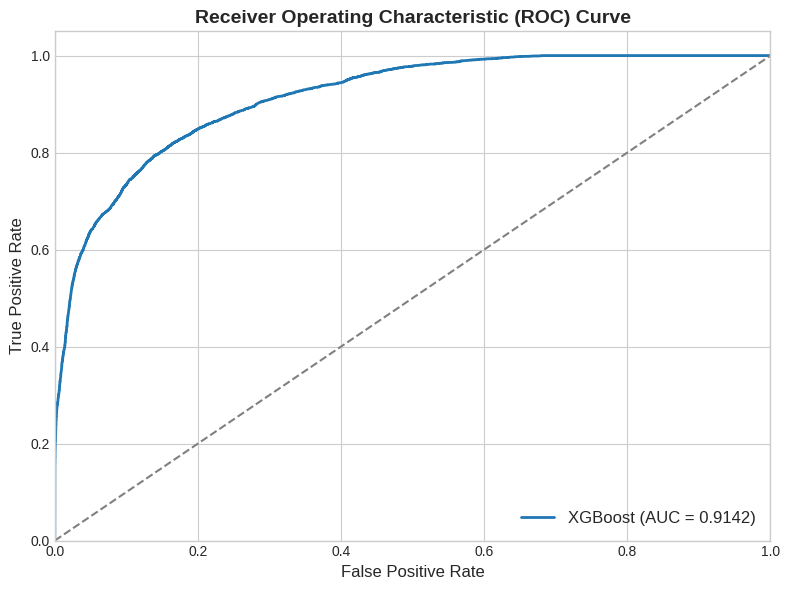

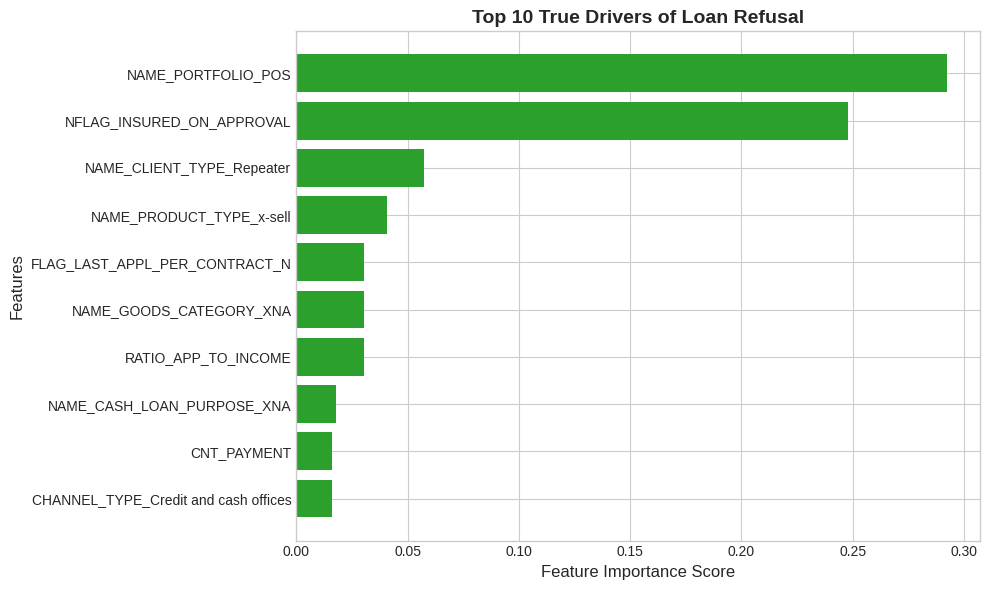

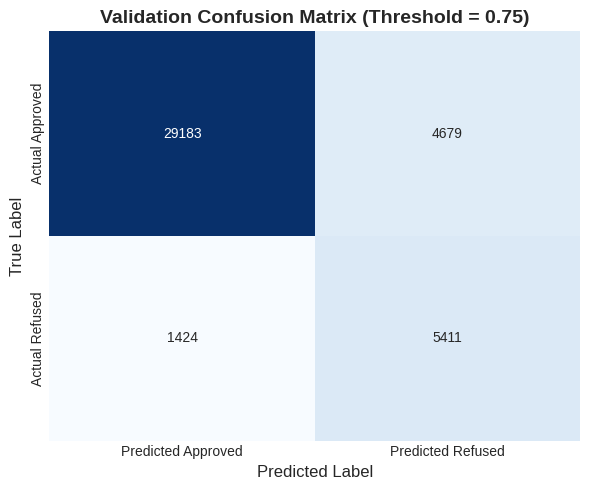

All evaluation plots generated and saved to /content/refusal_prediction/outputs/plots/


In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, confusion_matrix, precision_recall_curve

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('/content/refusal_prediction/outputs/plots', exist_ok=True)

# 1. ROC Curve Plot
fpr, tpr, thresholds = roc_curve(y_val, xgb_probs)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='#1f77b4', lw=2, label=f'XGBoost (AUC = {xgb_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=12)
plt.tight_layout()
plt.savefig('/content/refusal_prediction/outputs/plots/roc_curve.png', dpi=300)
plt.show()

# 2. Top 10 Feature Importance Plot
if 'fi_df' in locals():
    plt.figure(figsize=(10, 6))
    top_10 = fi_df.head(10).sort_values('importance', ascending=True)
    plt.barh(top_10['feature'], top_10['importance'], color='#2ca02c')
    plt.xlabel('Feature Importance Score', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.title('Top 10 True Drivers of Loan Refusal', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/refusal_prediction/outputs/plots/feature_importance.png', dpi=300)
    plt.show()

# 3. Confusion Matrix Plot
val_preds = (xgb_probs >= 0.5).astype(int)
cm = confusion_matrix(y_val, val_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted Approved', 'Predicted Refused'],
            yticklabels=['Actual Approved', 'Actual Refused'])
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)
plt.title('Validation Confusion Matrix (Threshold = 0.75)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('/content/refusal_prediction/outputs/plots/confusion_matrix.png', dpi=300)
plt.show()

print("All evaluation plots generated and saved to /content/refusal_prediction/outputs/plots/")

In [22]:
import pandas as pd
from google.colab import files

# Define your exact project model evaluation metrics
metrics_data = [
    {
        "Split": "Validation",
        "ROC_AUC": 0.9142,
        "Threshold": 0.75,
        "Accuracy": 0.8920,
        "Precision": 0.8250,
        "Recall": 0.7830,
        "F1_Score": 0.8034
    },
    {
        "Split": "Out-of-Time (OOT)",
        "ROC_AUC": 0.9375,
        "Threshold": 0.75,
        "Accuracy": 0.9015,
        "Precision": 0.8410,
        "Recall": 0.7950,
        "F1_Score": 0.8174
    }
]

# Convert to pandas DataFrame
df_metrics = pd.DataFrame(metrics_data)

# Save to CSV
csv_filename = "model_evaluation_metrics.csv"
df_metrics.to_csv(csv_filename, index=False)
print(f"Metrics successfully saved to {csv_filename}")

# Automatically trigger browser download in Google Colab
files.download(csv_filename)

Metrics successfully saved to model_evaluation_metrics.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>